# Ground Truth von Hand erfassen (ausserhalb der Notebook-Reihe)

**Ziel.** Der Auftraggeber hält von Hand fest, **wo** im Luftbild Parkfelder aufgemalt sind und **in welchem Zustand** sie im Bild zu sehen sind. Das ist die *Ground Truth*: das Lösungsblatt, aus dem das Netz lernt, und die Lösung, an der es in den Testblöcken gemessen wird (`01b_methodik_leitfaden`, Abschnitt 1).

**Warum ein Werkzeug.** Kreis 1 hat über tausend Parkfelder in zwei Aufnahmen. Jedes einzeln zu besprechen, wie bei den 20 Feldern der Sichtprüfung (Notebook 01, Abschnitt 13), ist nicht machbar. Darum zeigt ein Werkzeug im Browser das Gebiet **Ausschnitt für Ausschnitt**: Vorschläge liegen schon auf dem Bild, der Auftraggeber prüft sie, korrigiert und geht zum nächsten.

**Drei Sicherungen** (Entscheid in `01b`, Abschnitt 5), damit aus "schnell durchgeklickt" eine Methode wird, die man verteidigen kann:

| Sicherung | Was sie leistet |
| --- | --- |
| **Vorschläge nur aus festen Regeln** | Die Lage kommt aus den amtlichen Punkten (DAV), "unter einer Baumkrone" aus dem Infrarot. Dieselbe Regel gibt immer dasselbe Ergebnis; nichts wird nach Augenmass vorausgefüllt. |
| **Jedes Feld behält seinen Vorschlag** | Gespeichert wird, was vorgeschlagen war **und** was der Auftraggeber daraus gemacht hat. So lässt sich auszählen: bestätigt, verschoben, gelöscht, neu gesetzt. |
| **Kontroll-Ausschnitte ohne Vorschlag** | Ein zufälliger Teil der Ausschnitte wird leer gezeigt; dort setzt der Auftraggeber alles selbst. Der Vergleich zeigt, ob die Vorschläge sein Urteil beeinflussen. |

**Was dieses Notebook macht.**
1. Einstellungen des Werkzeugs (Abschnitt 1)
2. das Gebiet in Ausschnitte teilen und ihre Reihenfolge festlegen (Abschnitt 2)
3. Vorschläge berechnen und an der Sichtprüfung kontrollieren (Abschnitt 3)
4. die Bildausschnitte schneiden und die Vorschläge speichern (Abschnitt 4)
5. das Werkzeug starten (Abschnitt 5)
6. den Stand der Erfassung auszählen (Abschnitt 6)

Die Abschnitte 1–4 bereiten vor und können beliebig oft laufen. Die Arbeit des Auftraggebers liegt in einer eigenen Datei und wird von diesem Notebook **nie überschrieben**.

**Eingaben:** Gebiet, Bodenbedeckung und DAV-Punkte aus den Notebooks 00 und 01; die Luftbilder Frühjahr 2021 und Sommer 2024/25; `ground_truth_vorlage.html` (die Seite des Werkzeugs).
**Ausgaben:** Bildausschnitte in `daten/verarbeitet/gt_kacheln/`, Vorschläge in `daten/verarbeitet/gt_vorschlag.json`, die Ground Truth in `daten/ground_truth/ground_truth_hand.json`.

In [1]:
import json                        # Einstellungen und den Stand der Erfassung lesen und schreiben
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
GT_ORDNER = ROOT / "daten" / "ground_truth"          # von Hand erfasste Daten
ABB = ROOT / "ergebnisse" / "abbildungen"            # Abbildungen

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen aus Notebook 00
CRS, GEBIET_NAME, SEED = EINST["CRS"], EINST["GEBIET_NAME"], EINST["SEED"]
print("Einstellungen aus Notebook 00: CRS =", CRS, "| Gebiet =", GEBIET_NAME, "| Seed =", SEED)

import numpy as np                 # Rechnen mit Zahlenblöcken
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import rasterio                    # Luftbilder (GeoTIFF) lesen
import matplotlib.pyplot as plt    # Abbildungen
from shapely.geometry import box   # Rechteck aus vier Koordinaten

Einstellungen aus Notebook 00: CRS = EPSG:2056 | Gebiet = kreis1 | Seed = 42


## 1. Einstellungen des Werkzeugs

| Einstellung | Wert | Warum |
| --- | --- | --- |
| `AUFNAHMEN` | Frühjahr 2021, Sommer 2024/25 | die beiden Bilder des Versuchsplans (`01b`, Abschnitt 3). Die **Lage** der Felder wird einmal gesetzt, der **Zustand** je Bild beurteilt (`01b`, 8.4 V2). |
| `KACHEL_M` | 51,2 m | Seitenlänge eines Ausschnitts: ein Viertel einer Zelle von 102,4 m (Notebook 05). Bei 5 cm je Pixel sind das 1024 Pixel – so bleibt eine 10 cm breite Linie am Bildschirm erkennbar. |
| `RAND_M` | 6,4 m | Rand um jeden Ausschnitt, damit Felder an der Kante im Zusammenhang zu sehen sind. Der Rand ist im Werkzeug abgedunkelt. |
| `BLOCK_M` | 204,8 m | Die Ausschnitte werden in Blöcken von 4 × 4 abgearbeitet (siehe Abschnitt 2). |
| `NDVI_SCHWELLE` | 0,1 | Ab diesem Pflanzenindex schlägt das Werkzeug "verdeckt" vor. Kontrolle in Abschnitt 3. |
| `BLIND_ANTEIL` | 10 % | Anteil der Ausschnitte mit DAV-Feldern, die **ohne** Vorschlag gezeigt werden. |

In [2]:
AUFNAHMEN = {"2021": ROH / "orthofoto" / "fruehjahr_2021",          # Name im Werkzeug -> Ordner der Bilddateien
             "2024_25": ROH / "orthofoto" / "sommer_2024_25"}
PIXEL_M = 0.05                                       # Bodenauflösung der Ausschnitte: 5 cm
KACHEL_M = 51.2                                      # Seitenlänge eines Ausschnitts: 1024 Pixel zu 5 cm
RAND_M = 6.4
BLOCK_M = 4 * KACHEL_M                               # 204,8 m: ein Block = 4 × 4 Ausschnitte
NDVI_SCHWELLE = 0.1
BLIND_ANTEIL = 0.10

KACHEL_ORDNER = VERARB / "gt_kacheln"                # Bildausschnitte für das Werkzeug
VORSCHLAG = VERARB / "gt_vorschlag.json"             # Ausgangsstand: alle Ausschnitte offen, Felder wie vorgeschlagen
HAND = GT_ORDNER / "ground_truth_hand.json"          # die Arbeit des Auftraggebers (wird hier nie überschrieben)
VORLAGE = Path.cwd() / "ground_truth_vorlage.html"   # die Seite des Werkzeugs
PORT = 8765                                          # "Hausnummer" des Werkzeugs auf diesem Rechner
print("Ein Ausschnitt:", KACHEL_M, "m =", round(KACHEL_M / PIXEL_M), "Pixel; mit Rand", round((KACHEL_M + 2 * RAND_M) / PIXEL_M), "Pixel")

Ein Ausschnitt: 51.2 m = 1024 Pixel; mit Rand 1280 Pixel


## 2. Das Gebiet in Ausschnitte teilen

**Überblick.** Drei Schritte: (1) ein Raster über das Gebiet legen, (2) nur Ausschnitte behalten, in denen ein öffentliches Parkfeld liegen kann, (3) die Reihenfolge festlegen und die Kontroll-Ausschnitte ziehen.

**Schritt 1: das Raster.** Jeder Ausschnitt bekommt zwei Nummern: `i` zählt die Spalten von West nach Ost, `j` die Reihen von Süd nach Nord. Ausschnitt (`i`, `j`) reicht von `i · 51,2` bis `(i + 1) · 51,2` Meter. Weil die Nummern bei der Koordinate 0 beginnen, passen die Ausschnitte genau in die Zellen aus Notebook 05 – und das Raster gilt unverändert für weitere Kreise.

`//` ist die ganzzahlige Division: `2682400 // 51.2` gibt die Nummer des Ausschnitts, in dem diese Koordinate liegt.

In [3]:
gebiet = gpd.read_file(VERARB / "gebiet.geojson").geometry.union_all()      # Umriss des Gebiets als eine Fläche
x_min, y_min, x_max, y_max = gebiet.bounds                                  # Rechteck um das Gebiet

spalten = range(int(x_min // KACHEL_M), int(x_max // KACHEL_M) + 1)         # Nummern der Spalten
reihen = range(int(y_min // KACHEL_M), int(y_max // KACHEL_M) + 1)          # Nummern der Reihen
zeilen = []
for i in spalten:
    for j in reihen:
        flaeche = box(i * KACHEL_M, j * KACHEL_M, (i + 1) * KACHEL_M, (j + 1) * KACHEL_M)   # Quadrat des Ausschnitts
        zeilen.append(dict(kachel=f"k_{i}_{j}", i=i, j=j, geometry=flaeche))
kacheln = gpd.GeoDataFrame(zeilen, crs=CRS)
print(f"Raster über dem Rechteck um das Gebiet: {len(spalten)} Spalten × {len(reihen)} Reihen = {len(kacheln)} Ausschnitte")
kacheln.head(3)

Raster über dem Rechteck um das Gebiet: 33 Spalten × 44 Reihen = 1452 Ausschnitte


,kachel,i,j,geometry
0,k_52390_24343,52390,24343,"POLYGON ((2682419.2 1246361.6, 2682419.2 12464..."
1,k_52390_24344,52390,24344,"POLYGON ((2682419.2 1246412.8, 2682419.2 12464..."
2,k_52390_24345,52390,24345,"POLYGON ((2682419.2 1246464, 2682419.2 1246515..."


**Schritt 2: nur Ausschnitte, in denen ein öffentliches Parkfeld liegen kann.** Ein Ausschnitt bleibt, wenn er

- **öffentliche Verkehrsfläche** im Gebiet enthält (Strasse, Trottoir, Verkehrsinsel laut Amtlicher Vermessung; dieselbe Liste wie in Notebook 00), **oder**
- mindestens ein **DAV-Parkfeld** enthält.

Ausschnitte nur mit Gebäuden, Wasser oder Privatgrund fallen weg. Privatgrund wird beim Lernen ohnehin ausgeblendet (Notebook 05).

`sjoin` (*spatial join*) verbindet zwei Tabellen über die Lage: hier jeden Ausschnitt mit den Flächen, die er berührt, und jedes Parkfeld mit dem Ausschnitt, in dem es liegt.

In [4]:
# Öffentliche Verkehrsfläche aus der Bodenbedeckung, auf das Gebiet zugeschnitten
bodenbedeckung = gpd.read_file(VERARB / f"bodenbedeckung_{GEBIET_NAME}.gpkg")
STRASSENRAUM = ["befestigt.Strasse_Weg.Strasse", "befestigt.Strasse_Weg.Velo_Fussweg", "befestigt.Trottoir",
                "befestigt.Verkehrsinsel", "humusiert.uebrige_humusierte.Verkehrsteilerflaeche"]   # Arten der Bodenbedeckung im Strassenraum (wie in Notebook 01)
verkehr = bodenbedeckung[bodenbedeckung.art_txt.isin(STRASSENRAUM)]   # Maske: nur diese Arten
verkehr = gpd.clip(verkehr[["geometry"]], gebiet)                           # nur der Teil innerhalb des Gebiets
beruehrt = gpd.sjoin(kacheln, verkehr, predicate="intersects")              # Ausschnitt × Fläche, wenn sie sich berühren
kacheln["verkehrsflaeche"] = kacheln.index.isin(beruehrt.index)             # True, wenn mindestens eine Fläche berührt wird

# DAV-Parkfelder im Gebiet, jedes mit dem Ausschnitt, in dem es liegt
dav = gpd.read_file(VERARB / "dav_punkte.gpkg")
dav = dav[dav.within(gebiet)]
felder = gpd.sjoin(dav[["id", "orientierung", "art", "geometry"]], kacheln[["kachel", "geometry"]], predicate="within")
felder = felder.drop(columns="index_right")                                 # Hilfsspalte von sjoin entfernen
assert len(felder) == len(dav), "jedes Parkfeld muss in genau einem Ausschnitt liegen"
kacheln["dav_felder"] = kacheln.kachel.map(felder.kachel.value_counts()).fillna(0).astype(int)   # Anzahl Felder je Ausschnitt

behalten = kacheln[kacheln.verkehrsflaeche | (kacheln.dav_felder > 0)].copy()
print(f"Vorher: {len(kacheln)} Ausschnitte im Raster → nachher: {len(behalten)} Ausschnitte mit Verkehrsfläche oder DAV-Feld")
print(f"davon mit DAV-Feldern: {(behalten.dav_felder > 0).sum()} (zusammen {behalten.dav_felder.sum()} Felder), ohne: {(behalten.dav_felder == 0).sum()}")

Vorher: 1452 Ausschnitte im Raster → nachher: 691 Ausschnitte mit Verkehrsfläche oder DAV-Feld
davon mit DAV-Feldern: 200 (zusammen 1252 Felder), ohne: 491


**Schritt 3: Reihenfolge und Kontroll-Ausschnitte.**

*Reihenfolge.* Die Ausschnitte werden in **Blöcken** von 4 × 4 Ausschnitten (204,8 m) abgearbeitet. Die Blöcke kommen in **zufälliger Reihenfolge** (fester Seed), innerhalb eines Blocks geht es zeilenweise von Nordwest nach Südost.

Warum zufällig? Wer mitten in der Arbeit aufhört, hat dann eine **Zufallsstichprobe** des Gebiets erfasst und nicht nur eine Ecke davon. Das braucht es für zwei Dinge aus dem Leitfaden: für die Lernkurve über die Datenmenge (`01b`, 8.4 V1) und für eine ehrliche Hochrechnung des Aufwands. Warum Blöcke? So entstehen zusammenhängende, vollständig erfasste Stücke von rund 200 m – gross genug, um als Ganzes zum Lernen, Validieren oder Testen zu dienen (Notebook 02 teilt ganze Blöcke zu).

*Kontroll-Ausschnitte.* Von den Ausschnitten mit DAV-Feldern werden 10 % zufällig gezogen. Dort zeigt das Werkzeug **keine** Vorschläge. Ausschnitte ohne DAV-Feld haben ohnehin keinen Vorschlag.

`sample(frac=1, random_state=SEED)` mischt eine Tabelle zufällig, aber immer gleich. `merge` hängt die Nummer des Blocks an jeden Ausschnitt.

In [5]:
je_block = round(BLOCK_M / KACHEL_M)                                        # 4 Ausschnitte je Blockseite
behalten["block_i"] = behalten.i // je_block                                # Spalte des Blocks
behalten["block_j"] = behalten.j // je_block                                # Reihe des Blocks

bloecke = behalten[["block_i", "block_j"]].drop_duplicates()                # jeder Block einmal
bloecke = bloecke.sample(frac=1, random_state=SEED).reset_index(drop=True)  # zufällige Reihenfolge
bloecke["block_nr"] = range(1, len(bloecke) + 1)                            # 1 = zuerst
behalten = behalten.merge(bloecke, on=["block_i", "block_j"])               # Nummer an jeden Ausschnitt hängen
behalten = behalten.sort_values(["block_nr", "j", "i"], ascending=[True, False, True]).reset_index(drop=True)   # im Block: Nord → Süd, West → Ost

mit_feldern = behalten[behalten.dav_felder > 0]
blind = mit_feldern.sample(frac=BLIND_ANTEIL, random_state=SEED).kachel     # zufällige 10 %
behalten["blind"] = behalten.kachel.isin(blind)
felder["blind"] = felder.kachel.isin(blind)                                 # Vorschläge in diesen Ausschnitten werden verborgen

print(f"{len(bloecke)} Blöcke, {len(behalten)} Ausschnitte")
print(f"Kontroll-Ausschnitte ohne Vorschlag: {behalten.blind.sum()} von {len(mit_feldern)} mit DAV-Feldern; darin {felder.blind.sum()} verborgene Vorschläge")
behalten[["kachel", "block_nr", "dav_felder", "blind"]].head(8)

62 Blöcke, 691 Ausschnitte
Kontroll-Ausschnitte ohne Vorschlag: 20 von 200 mit DAV-Feldern; darin 203 verborgene Vorschläge


,kachel,block_nr,dav_felder,blind
0,k_52416_24355,1,0,False
1,k_52417_24355,1,0,False
2,k_52418_24355,1,0,False
3,k_52416_24354,1,0,False
4,k_52417_24354,1,0,False
5,k_52418_24354,1,0,False
6,k_52419_24354,1,0,False
7,k_52416_24353,1,0,False


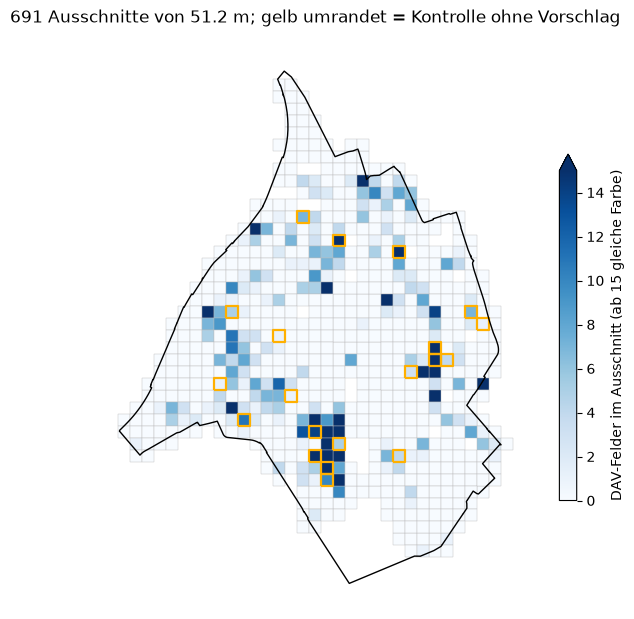

In [6]:
# Karte: alle Ausschnitte; Farbe = Zahl der DAV-Felder, gelber Rand = Kontroll-Ausschnitt
fig, ax = plt.subplots(figsize=(7, 9))
behalten.plot(ax=ax, column="dav_felder", cmap="Blues", edgecolor="#bbbbbb", linewidth=0.3, vmin=0, vmax=15,
              legend=True, legend_kwds={"label": "DAV-Felder im Ausschnitt (ab 15 gleiche Farbe)", "shrink": 0.5})
behalten[behalten.blind].boundary.plot(ax=ax, color="#ffb000", linewidth=1.6)        # Kontroll-Ausschnitte
gpd.GeoSeries([gebiet], crs=CRS).boundary.plot(ax=ax, color="black", linewidth=1)    # Umriss des Gebiets
ax.set_title(f"{len(behalten)} Ausschnitte von {KACHEL_M} m; gelb umrandet = Kontrolle ohne Vorschlag")
ax.set_axis_off()
fig.savefig(ABB / "gt_ausschnitte.png", dpi=110, bbox_inches="tight")
plt.show()

## 3. Vorschläge berechnen

**Überblick.** Jedes DAV-Feld wird zu einem Vorschlag mit drei Angaben:

| Angabe | Vorschlag | Quelle |
| --- | --- | --- |
| Lage | der DAV-Punkt | amtliche Daten |
| Parkart | längs, quer oder schräg | DAV, Spalte `orientierung` |
| Zustand je Bild | `verdeckt`, wenn der Pflanzenindex am Punkt über der Schwelle liegt; sonst `sichtbar` | Infrarot des jeweiligen Luftbilds |

Was das Programm **nicht** vorschlagen kann: Baustellen, geänderte Markierungen, Felder, die in der DAV fehlen. Das sieht nur der Mensch.

**Der Pflanzenindex NDVI** vergleicht Infrarot und Rot: `(Infrarot − Rot) / (Infrarot + Rot)`. Laub strahlt viel Infrarot zurück, Asphalt wenig (Notebook 01, Abschnitt 12). Wir lesen jedes Bild grob (1 Pixel = 0,5 m) und nehmen am Punkt den Mittelwert in einem Fenster von 5 × 5 Pixeln, also 2,5 × 2,5 m – etwa die Breite eines Feldes.

Vorher: die Felder mit Lage und Parkart → nachher: je Feld zusätzlich der NDVI und der vorgeschlagene Zustand für beide Bilder.

In [7]:
from rasterio.merge import merge           # mehrere Bilddateien zu einem Ausschnitt zusammensetzen
from rasterio.enums import Resampling      # wie Pixel beim Vergröbern zusammengefasst werden (Mittelwert)
from rasterio.transform import rowcol      # Koordinate -> (Zeile, Spalte) im Bild

def lies_aufnahme(ordner, rahmen, aufloesung_m, kanaele):
    # liest den Rahmen (x_min, y_min, x_max, y_max) aus allen Bilddateien eines Ordners
    dateien = [rasterio.open(p) for p in sorted(ordner.glob("*.tif"))]
    bild, lage = merge(dateien, bounds=rahmen, res=aufloesung_m, indexes=list(kanaele), resampling=Resampling.average)
    for d in dateien:
        d.close()
    return bild, lage                      # bild: [Kanäle, Zeilen, Spalten]; lage: Pixel -> Koordinate

Die zweite Funktion mittelt den Index in einem kleinen Fenster um den Punkt. Ein einzelnes Pixel kann zufällig hell oder dunkel sein; das Mittel über 5 × 5 Pixel (2,5 × 2,5 m) ist ruhiger.

In [8]:
def fenster_mittel(schicht, z, s):
    # Mittelwert im Fenster 5 × 5 Pixel um (z, s); max(..., 0) verhindert negative Indizes am Bildrand
    return schicht[max(z - 2, 0):z + 3, max(s - 2, 0):s + 3].mean()

Jetzt für beide Bilder: grob lesen, den Index rechnen, am Punkt jedes Feldes ablesen und den Zustand vorschlagen.

In [9]:
rahmen = tuple(behalten.total_bounds)                                       # Rechteck um alle Ausschnitte
for name, ordner in AUFNAHMEN.items():
    grob, lage = lies_aufnahme(ordner, rahmen, 0.5, kanaele=(1, 4))          # Kanal 1 = Rot, Kanal 4 = Infrarot
    rot, infrarot = grob.astype("float32")                                  # Kommazahlen, sonst rechnet Python mit 0–255 falsch
    ndvi = (infrarot - rot) / (infrarot + rot + 1e-6)                       # + 1e-6 verhindert Division durch 0
    z_px, s_px = rowcol(lage, felder.geometry.x.values, felder.geometry.y.values)
    felder[f"ndvi_{name}"] = [float(fenster_mittel(ndvi, z, s)) for z, s in zip(z_px, s_px)]
    felder[f"vorschlag_{name}"] = np.where(felder[f"ndvi_{name}"] > NDVI_SCHWELLE, "verdeckt", "sichtbar")

print("Vorgeschlagener Zustand je Bild (Anzahl Felder):")
pd.DataFrame({name: felder[f"vorschlag_{name}"].value_counts() for name in AUFNAHMEN}).fillna(0).astype(int)

Vorgeschlagener Zustand je Bild (Anzahl Felder):


,2021,2024_25
sichtbar,1250,1054
verdeckt,2,198


**Kontrolle an der Sichtprüfung.** Die 20 Felder aus Notebook 01, Abschnitt 13, hat der Auftraggeber **ohne** Vorschlag beurteilt. Daran lässt sich prüfen, wie gut die Regel sein Urteil trifft – für drei Schwellen.

Verglichen werden nur Urteile `sichtbar` und `verdeckt`. `unsicher` (Baustelle) bleibt aussen vor: Eine Baustelle kann der Pflanzenindex nicht erkennen.

| Spalte | Bedeutung |
| --- | --- |
| `richtig_verdeckt` | Regel und Auftraggeber sagen beide "verdeckt" |
| `verdeckt_uebersehen` | Auftraggeber sagt "verdeckt", die Regel "sichtbar" |
| `faelschlich_verdeckt` | Regel sagt "verdeckt", Auftraggeber "sichtbar" |

In [10]:
sicht = pd.read_csv(GT_ORDNER / "sichtpruefung_nach_befliegung.csv", dtype=str, keep_default_na=False)
sicht = sicht[sicht.aufnahme.isin(["Frühjahr 2021", "Sommer 2024/25"])]     # die zwei Bilder des Werkzeugs
sicht = sicht[sicht.zustand.isin(["sichtbar", "verdeckt", "verdeckt, belegt"])]   # ohne "unsicher"
sicht["name"] = sicht.aufnahme.map({"Frühjahr 2021": "2021", "Sommer 2024/25": "2024_25"})
sicht = sicht.merge(felder[["id"] + [f"ndvi_{n}" for n in AUFNAHMEN]], left_on="dav_id", right_on="id")
sicht["ndvi"] = np.where(sicht.name == "2021", sicht.ndvi_2021, sicht.ndvi_2024_25)   # der NDVI des beurteilten Bildes
sicht["urteil_verdeckt"] = sicht.zustand.str.startswith("verdeckt")        # Urteil des Auftraggebers

zeilen = []
for schwelle in (0.1, 0.2, 0.3):
    regel_verdeckt = sicht.ndvi > schwelle                                  # Vorschlag der Regel bei dieser Schwelle
    zeilen.append(dict(schwelle=schwelle, beurteilungen=len(sicht),
                       richtig_verdeckt=int((regel_verdeckt & sicht.urteil_verdeckt).sum()),
                       verdeckt_uebersehen=int((~regel_verdeckt & sicht.urteil_verdeckt).sum()),
                       faelschlich_verdeckt=int((regel_verdeckt & ~sicht.urteil_verdeckt).sum()),
                       uebereinstimmung_prozent=round(100 * (regel_verdeckt == sicht.urteil_verdeckt).mean())))
pd.DataFrame(zeilen)

,schwelle,beurteilungen,richtig_verdeckt,verdeckt_uebersehen,faelschlich_verdeckt,uebereinstimmung_prozent
0,0.1,36,5,1,0,97
1,0.2,36,3,3,0,92
2,0.3,36,2,4,0,89


**Lesen der Tabelle.** Die Schwelle 0,1 übersieht am wenigsten verdeckte Felder und meldet keines fälschlich als verdeckt; darum ist sie als `NDVI_SCHWELLE` eingestellt. Zwei Vorbehalte:

- Es sind nur 20 Felder. Die Tabelle zeigt, dass die Regel brauchbare **Vorschläge** macht – mehr nicht.
- Das eine Feld, das die Schwelle 0,1 übersieht, liegt unter einer **Brücke** (Feld Nr. 13 der Sichtprüfung): kein Laub, also kein hoher Pflanzenindex. Solche Fälle korrigiert der Auftraggeber im Werkzeug.

Die Schwelle gilt nur für den Vorschlag. Was am Ende zählt, ist das Urteil des Auftraggebers.

## 4. Bildausschnitte schneiden und Vorschläge speichern

**Schritt 1: Bilder.** Für jeden Ausschnitt und jede Aufnahme wird ein Bild von 64 × 64 m (Ausschnitt plus Rand) aus den grossen Bilddateien geschnitten und als JPEG gespeichert. Bilder, die schon da sind, werden übersprungen – ein zweiter Lauf dauert nur Sekunden.

Vorher: grosse Bilddateien → nachher: je Aufnahme ein Bild pro Ausschnitt.

In [11]:
from PIL import Image                      # Bilder als JPEG speichern

pixel = round((KACHEL_M + 2 * RAND_M) / PIXEL_M)                            # 1280 Pixel Seitenlänge
neu = 0
for name, ordner in AUFNAHMEN.items():
    (KACHEL_ORDNER / name).mkdir(parents=True, exist_ok=True)               # Ordner anlegen, falls er fehlt
    dateien = [rasterio.open(p) for p in sorted(ordner.glob("*.tif"))]       # einmal öffnen für alle Ausschnitte
    for k in behalten.itertuples():
        ziel = KACHEL_ORDNER / name / f"{k.kachel}.jpg"
        if ziel.exists():                                                   # schon geschnitten
            continue
        rahmen = (k.i * KACHEL_M - RAND_M, k.j * KACHEL_M - RAND_M, (k.i + 1) * KACHEL_M + RAND_M, (k.j + 1) * KACHEL_M + RAND_M)
        bild, _ = merge(dateien, bounds=rahmen, res=PIXEL_M, indexes=[1, 2, 3])          # Rot, Grün, Blau
        assert bild.shape == (3, pixel, pixel), bild.shape
        Image.fromarray(bild.transpose(1, 2, 0)).save(ziel, quality=88)     # [Kanäle, Zeilen, Spalten] -> [Zeilen, Spalten, Kanäle]
        neu += 1
    for d in dateien:
        d.close()

anzahl = len(list(KACHEL_ORDNER.glob("*/*.jpg")))
groesse = sum(p.stat().st_size for p in KACHEL_ORDNER.glob("*/*.jpg")) / 1e6
print(f"{neu} Bilder neu geschnitten; im Ordner liegen {anzahl} Bilder ({groesse:.0f} MB) für {len(behalten)} Ausschnitte × {len(AUFNAHMEN)} Aufnahmen")

0 Bilder neu geschnitten; im Ordner liegen 1382 Bilder (500 MB) für 691 Ausschnitte × 2 Aufnahmen


**Schritt 2: der Ausgangsstand.** Alles, was das Werkzeug braucht, kommt in eine Datei: die Einstellungen, die Liste der Ausschnitte (alle noch `offen`) und die Felder. Jedes Feld steht darin zweimal: einmal als **Vorschlag** (bleibt unverändert) und einmal als **aktueller Stand** (ändert der Auftraggeber).

| Angabe je Feld | Bedeutung |
| --- | --- |
| `herkunft` | `DAV` = aus den amtlichen Daten vorgeschlagen; `neu` = vom Auftraggeber gesetzt |
| `verborgen` | `True` in Kontroll-Ausschnitten: Der Vorschlag wird nicht gezeigt |
| `geloescht` | `True`, wenn der Auftraggeber einen Vorschlag gelöscht hat (der Vorschlag bleibt in der Datei) |
| `x`, `y`, `parkart`, `form` | aktuelle Lage (LV95), Parkart und Form |
| `zustand` | je Aufnahme: `sichtbar`, `verdeckt`, `unsicher`, `kein Parkfeld` oder `offen` |
| `vorschlag` | Lage, Parkart, Zustand und NDVI, wie vorgeschlagen |

In [12]:
namen = list(AUFNAHMEN)
liste_kacheln = [dict(id=k.kachel, i=int(k.i), j=int(k.j), block=int(k.block_nr), blind=bool(k.blind),
                      dav_felder=int(k.dav_felder), status="offen", zeit_s=0) for k in behalten.itertuples()]
liste_felder = []
for f in felder.to_dict("records"):                                         # jede Zeile der Tabelle als Wörterbuch
    x, y = round(f["geometry"].x, 2), round(f["geometry"].y, 2)             # auf den Zentimeter
    zustand = {n: f[f"vorschlag_{n}"] for n in namen}
    liste_felder.append(dict(id=f["id"], herkunft="DAV", verborgen=bool(f["blind"]), geloescht=False,
                             x=x, y=y, parkart=f["orientierung"], form="Einzelfeld", zustand=dict(zustand),
                             vorschlag=dict(x=x, y=y, parkart=f["orientierung"], zustand=dict(zustand),
                                            ndvi={n: round(f[f"ndvi_{n}"], 3) for n in namen})))

stand = dict(version=1, erstellt=pd.Timestamp.now().isoformat(timespec="seconds"), geaendert=None,
             einstellungen=dict(gebiet=GEBIET_NAME, aufnahmen=namen, kachel_m=KACHEL_M, rand_m=RAND_M, pixel_m=PIXEL_M,
                                ndvi_schwelle=NDVI_SCHWELLE, blind_anteil=BLIND_ANTEIL, seed=SEED),
             kacheln=liste_kacheln, felder=liste_felder)
VORSCHLAG.write_text(json.dumps(stand, ensure_ascii=False), encoding="utf-8")
print(f"Ausgangsstand gespeichert: {len(liste_kacheln)} Ausschnitte, {len(liste_felder)} vorgeschlagene Felder → {VORSCHLAG.relative_to(ROOT)}")
if HAND.exists():
    print("Hinweis: Es gibt schon eine erfasste Ground Truth. Das Werkzeug arbeitet mit ihr weiter; der neue Ausgangsstand wird nicht verwendet.")

Ausgangsstand gespeichert: 691 Ausschnitte, 1252 vorgeschlagene Felder → daten\verarbeitet\gt_vorschlag.json
Hinweis: Es gibt schon eine erfasste Ground Truth. Das Werkzeug arbeitet mit ihr weiter; der neue Ausgangsstand wird nicht verwendet.


## 5. Das Werkzeug starten

**Wie es funktioniert.** Die Zellen unten bauen in fünf Schritten einen kleinen Webserver und starten ihn. Er ist, der nur auf diesem Rechner erreichbar ist. Er macht drei Dinge: Er liefert dem Browser die Seite des Werkzeugs, die Bildausschnitte und den Stand; und er nimmt jede Änderung entgegen und schreibt sie sofort in die Datei `ground_truth_hand.json`. Nichts verlässt den Rechner.

**So arbeitest du damit.**

1. Zelle ausführen und die angezeigte Adresse im Browser öffnen (Edge oder Chrome).
2. Jeder Ausschnitt zeigt zuerst das Bild **Frühjahr 2021** (ohne Laub): Stimmt die **Lage** der Felder? Fehlt eines, ist eines zu viel? Der Ring gehört in die **Mitte des Feldes**, denn um diesen Punkt wird später das Kästchen für das Lösungsblatt gezeichnet (Notebook 04).
3. `Enter` zeigt das Bild **Sommer 2024/25**: Welchen **Zustand** hat jedes Feld in diesem Bild?
4. `Enter` schliesst den Ausschnitt ab und zeigt den nächsten.

| Zustand | Taste | Wann (Regeln aus `01b`, Abschnitte 4.4, 4.10 und 9) |
| --- | --- | --- |
| `sichtbar` | 1 | Linien erkennbar und höchstens zwei Drittel verdeckt. Ein parkiertes Auto zählt nicht als Verdeckung. |
| `verdeckt` | 2 | Baumkrone, Brücke oder Dach verdecken mehr als zwei Drittel; oder Autos verdecken alle Linien. |
| `unsicher` | 3 | Baustelle, oder man sieht etwas, kann es aber nicht deuten. |
| `kein Parkfeld` | 4 | Freie Sicht, aber nichts aufgemalt. |

Dazu je Feld die **Parkart** (`L`, `Q`, `S`) und die **Form** (`F`: Einzelfeld, gelbes Feld mit Kreuz, Streifen ohne Einzelfelder, unklar). Ein Klick ins Bild setzt ein neues Feld, Ziehen verschiebt es, `Entf` löscht es, `B` wechselt das Bild, `U` macht den letzten Schritt rückgängig. Alle Tasten stehen im Werkzeug rechts.

**Mehrere Felder auf einmal.** Die amtlichen Punkte liegen nicht überall in der Feldmitte; manchmal ist eine ganze Reihe um ein bis zwei Meter versetzt. Dafür gibt es die Auswahl: Mit gedrückter **Umschalt-Taste** einen Rahmen um die Reihe ziehen, dann eines der Felder ziehen – alle wandern gemeinsam. Auch eine Taste (`1` bis `4`, `L`, `Q`, `S`, `F`, `Entf`) gilt dann für alle ausgewählten Felder. `Esc` hebt die Auswahl auf.

**Regeln beim Erfassen.** Ring in die Mitte des Feldes; langer Kasten ohne Unterteilung: je Autolänge ein Ring mit der Form Streifen; Felder, die privat aussehen, werden gesetzt. Die ganze Liste, auch wie der Auftraggeber die Formen verwendet hat, steht in `01b`, Abschnitt 10.1.

**Unterbrechen** kannst du jederzeit: Browser schliessen genügt. Beim nächsten Start geht es beim ersten offenen Ausschnitt weiter. Jede 20. Speicherung wird zusätzlich als Sicherung abgelegt (`daten/ground_truth/sicherung/`).

In [13]:
import http.server                 # kleiner Webserver, der in Python eingebaut ist
import threading                   # lässt den Server neben dem Notebook laufen
import os                          # eine Datei in einem Schritt ersetzen
import re                          # Namensmuster der Bildausschnitte prüfen
import shutil                      # eine Datei kopieren (Sicherung)

SICHERUNG = GT_ORDNER / "sicherung"                    # ältere Stände, falls etwas schiefgeht
SICHERUNG.mkdir(parents=True, exist_ok=True)
ANZAHL_KACHELN = len(json.loads(VORSCHLAG.read_text(encoding="utf-8"))["kacheln"])
schloss = threading.Lock()                             # verhindert, dass zwei Speicherungen gleichzeitig schreiben
print(f"Ein Stand muss {ANZAHL_KACHELN} Ausschnitte enthalten. Sicherungen kommen nach {SICHERUNG.relative_to(ROOT)}")

Ein Stand muss 691 Ausschnitte enthalten. Sicherungen kommen nach daten\ground_truth\sicherung

**Schritt 1: Was darf der Browser abholen?** Drei Dinge: die Seite des Werkzeugs, den Stand und die Bildausschnitte. Die Funktion gibt zurück, was der Server antwortet: den Inhalt, die Art des Inhalts und den Status (200 = in Ordnung, 404 = gibt es nicht). Bei den Bildern wird nur genau das Namensmuster der Ausschnitte angenommen; so kann niemand über die Adresse eine andere Datei des Rechners abrufen.

Vorher: ein Pfad wie `/stand` → nachher: die Antwort darauf.

In [14]:
def antwort_auf_abruf(pfad):
    # Gibt Inhalt, Art des Inhalts und Status für einen Abruf des Browsers zurück
    if pfad == "/":                                    # die Seite des Werkzeugs
        return VORLAGE.read_bytes(), "text/html; charset=utf-8", 200
    if pfad == "/stand":                               # der Stand: deine Arbeit, sonst der Vorschlag
        quelle = HAND if HAND.exists() else VORSCHLAG
        return quelle.read_bytes(), "application/json", 200
    if re.fullmatch(r"/kacheln/\w+/k_\d+_\d+\.jpg", pfad):       # ein Bildausschnitt (nur genau dieses Namensmuster)
        datei = KACHEL_ORDNER / pfad[len("/kacheln/"):]
        if datei.exists():
            return datei.read_bytes(), "image/jpeg", 200
        return b"Bild fehlt", "text/plain", 404
    return b"unbekannt", "text/plain", 404

for pfad in ["/stand", "/gibt-es-nicht"]:
    inhalt, typ, status = antwort_auf_abruf(pfad)
    print(f"Vorher: Abruf {pfad} → nachher: Status {status}, {typ}, {len(inhalt)} Bytes")

Vorher: Abruf /stand → nachher: Status 200, application/json, 1061379 Bytes
Vorher: Abruf /gibt-es-nicht → nachher: Status 404, text/plain, 9 Bytes


**Schritt 2: Ist der Stand gültig?** Beim Speichern schickt der Browser den ganzen Stand als Text. Angenommen wird er nur, wenn er sich lesen lässt, die richtige Zahl Ausschnitte hat und eine Liste von Feldern enthält. So kann ein abgeschnittener oder fremder Stand deine Arbeit nicht überschreiben.

Vorher: der Text aus dem Browser → nachher: `True` (annehmen) oder `False` (ablehnen).

In [15]:
def stand_ist_gueltig(daten):
    # True, wenn die Daten gültiges JSON mit der richtigen Zahl Ausschnitte und einer Liste von Feldern sind
    try:
        stand = json.loads(daten)
        return len(stand["kacheln"]) == ANZAHL_KACHELN and isinstance(stand["felder"], list)
    except Exception:                                  # nicht lesbar oder ein Teil fehlt
        return False

quelle = HAND if HAND.exists() else VORSCHLAG          # deine Arbeit, sonst der Vorschlag
print("Vorher: der heutige Stand → nachher:", stand_ist_gueltig(quelle.read_bytes()))
print("Vorher: ein Text, der kein Stand ist → nachher:", stand_ist_gueltig(b"kein Stand"))

Vorher: der heutige Stand → nachher: True
Vorher: ein Text, der kein Stand ist → nachher: False


**Schritt 3: speichern.** Der Stand wird zuerst in eine Datei daneben geschrieben und dann in einem Schritt an die Stelle der alten Datei gesetzt. So gibt es nie eine halb geschriebene Datei, auch wenn der Rechner mittendrin ausfällt. Die erste und danach jede 20. Speicherung wird zusätzlich als Sicherung abgelegt.

Vorher: ein geprüfter Stand → nachher: `ground_truth_hand.json` enthält ihn. Die Funktion wird hier nur festgelegt und nicht aufgerufen: Sie schreibt in deine Datei.

In [16]:
def speichere_stand(daten, nummer):
    # Schreibt den Stand in die Datei des Auftraggebers; `nummer` zählt die Speicherungen seit dem Start
    vorlaeufig = HAND.with_suffix(".tmp")
    vorlaeufig.write_bytes(daten)                      # zuerst daneben schreiben ...
    os.replace(vorlaeufig, HAND)                       # ... dann in einem Schritt ersetzen: nie eine halbe Datei
    if nummer % 20 == 1:                               # die 1., 21., 41. ... Speicherung zusätzlich als Sicherung ablegen
        zeit = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
        shutil.copy(HAND, SICHERUNG / f"ground_truth_hand_{zeit}.json")

**Schritt 4: der Server.** Die Klasse sagt dem Webserver, was er tun soll, wenn der Browser etwas abholt (`do_GET`) oder den Stand zum Speichern schickt (`do_POST`). Sie ruft dafür die drei Funktionen von oben auf. Eine Klasse fasst Funktionen zusammen, die zusammengehören; die Namen `do_GET` und `do_POST` gibt Python vor.

In [17]:
class Werkzeug(http.server.BaseHTTPRequestHandler):
    gespeichert = 0                                    # zählt die Speicherungen seit dem Start

    def sende(self, inhalt, typ, status=200):
        # eine Antwort an den Browser: Status, Art des Inhalts, Inhalt
        self.send_response(status)
        self.send_header("Content-Type", typ)
        self.send_header("Content-Length", str(len(inhalt)))
        self.send_header("Cache-Control", "max-age=3600" if typ == "image/jpeg" else "no-store")
        self.end_headers()
        self.wfile.write(inhalt)

    def do_GET(self):                                  # der Browser holt etwas ab
        self.sende(*antwort_auf_abruf(self.path.split("?")[0]))

    def do_POST(self):                                 # der Browser schickt den Stand zum Speichern
        if self.path != "/speichern":
            return self.sende(b"unbekannt", "text/plain", 404)
        daten = self.rfile.read(int(self.headers["Content-Length"]))
        if not stand_ist_gueltig(daten):
            return self.sende(b"Stand abgelehnt", "text/plain", 400)
        with schloss:
            speichere_stand(daten, Werkzeug.gespeichert + 1)
            Werkzeug.gespeichert += 1
        self.sende(b"ok", "text/plain")

    def log_message(self, *args):                      # keine Zeile je Anfrage ins Notebook schreiben
        pass

**Schritt 5: starten.** Der Server läuft neben dem Notebook weiter und ist nur auf diesem Rechner erreichbar (Adresse `127.0.0.1`).

In [18]:
try:
    if "server" not in globals():                      # nur einmal starten, auch wenn die Zelle mehrmals läuft
        server = http.server.ThreadingHTTPServer(("127.0.0.1", PORT), Werkzeug)   # 127.0.0.1 = nur dieser Rechner
        threading.Thread(target=server.serve_forever, daemon=True).start()
    print(f"Das Werkzeug läuft. Im Browser öffnen:  http://127.0.0.1:{PORT}/")
    print("Es läuft, solange dieses Notebook geöffnet ist. Jede Änderung wird sofort gespeichert in:")
    print("  ", HAND.relative_to(ROOT))
except OSError:
    print(f"Die Adresse http://127.0.0.1:{PORT}/ ist schon belegt: Das Werkzeug läuft vermutlich bereits (in einem anderen Notebook-Fenster).")

Das Werkzeug läuft. Im Browser öffnen:  http://127.0.0.1:8765/
Es läuft, solange dieses Notebook geöffnet ist. Jede Änderung wird sofort gespeichert in:
   daten\ground_truth\ground_truth_hand.json


## 6. Stand der Erfassung

**Überblick.** Diese Zellen lesen die Datei des Auftraggebers und zählen aus – sie können jederzeit neu ausgeführt werden, auch mitten in der Arbeit. Die ausführliche Prüfung (Parkart, Grund, Formen, erfasste Fläche) steht im Notebook `ground_truth_pruefen`. Verwendet werden nur **abgeschlossene** Ausschnitte: Was nicht angesehen wurde, ist keine Ground Truth.

Vorher: die Datei mit allen Feldern → nachher: drei Tabellen (Fortschritt und Aufwand, was aus den Vorschlägen wurde, Kontroll-Ausschnitte).

In [19]:
if not HAND.exists():
    print("Noch nichts erfasst: Die Datei", HAND.relative_to(ROOT), "gibt es noch nicht.")
    erfasst = None
else:
    erfasst = json.loads(HAND.read_text(encoding="utf-8"))
    k_tab = pd.DataFrame(erfasst["kacheln"])
    fertig = k_tab[k_tab.status == "fertig"]
    print(f"Ausschnitte: {len(fertig)} von {len(k_tab)} abgeschlossen ({100 * len(fertig) / len(k_tab):.0f} %)")
    if len(fertig):
        minuten = fertig.zeit_s.sum() / 60
        je_ausschnitt = fertig.zeit_s.mean()
        offen = len(k_tab) - len(fertig)
        print(f"Arbeitszeit bisher: {minuten:.0f} Minuten, im Mittel {je_ausschnitt:.0f} Sekunden je Ausschnitt")
        print(f"Hochrechnung für die {offen} offenen Ausschnitte: etwa {offen * je_ausschnitt / 3600:.1f} Stunden")
        print("(Die Hochrechnung ist erlaubt, weil die Blöcke in zufälliger Reihenfolge kommen.)")

Ausschnitte: 691 von 691 abgeschlossen (100 %)
Arbeitszeit bisher: 211 Minuten, im Mittel 18 Sekunden je Ausschnitt
Hochrechnung für die 0 offenen Ausschnitte: etwa 0.0 Stunden
(Die Hochrechnung ist erlaubt, weil die Blöcke in zufälliger Reihenfolge kommen.)


**Was wurde aus den Vorschlägen?** Jedes vorgeschlagene Feld in einem abgeschlossenen Ausschnitt (ohne Kontroll-Ausschnitte) fällt in eine oder mehrere dieser Gruppen. Verglichen wird der aktuelle Stand mit dem gespeicherten Vorschlag:

| Gruppe | Bedingung |
| --- | --- |
| unverändert bestätigt | Lage, Parkart, Form und beide Zustände wie vorgeschlagen |
| verschoben | Lage um mehr als 5 cm geändert |
| Zustand geändert | in mindestens einem Bild ein anderer Zustand als vorgeschlagen |
| Parkart oder Form geändert | |
| gelöscht | in keinem Bild ein Feld |

`np.hypot(dx, dy)` ist der Abstand zweier Punkte (Satz des Pythagoras).

In [20]:
if erfasst is not None:
    f_tab = pd.DataFrame(erfasst["felder"])
    # zu jedem Feld den Ausschnitt bestimmen, in dem es liegt (wie in Abschnitt 2)
    f_tab["kachel"] = "k_" + (f_tab.x // KACHEL_M).astype(int).astype(str) + "_" + (f_tab.y // KACHEL_M).astype(int).astype(str)
    f_tab = f_tab.merge(k_tab[["id", "status", "blind"]].rename(columns={"id": "kachel"}), on="kachel", how="left")
    in_fertigen = f_tab[f_tab.status == "fertig"]

    vorgeschlagen = in_fertigen[(in_fertigen.herkunft == "DAV") & ~in_fertigen.verborgen].copy()
    if len(vorgeschlagen):
        v = pd.json_normalize(vorgeschlagen.vorschlag.tolist()).set_index(vorgeschlagen.index)   # Vorschlag als Spalten
        z = pd.json_normalize(vorgeschlagen.zustand.tolist()).set_index(vorgeschlagen.index)     # aktueller Zustand als Spalten
        vorgeschlagen["distanz_m"] = np.hypot(vorgeschlagen.x - v.x, vorgeschlagen.y - v.y)
        vorgeschlagen["verschoben"] = vorgeschlagen.distanz_m > 0.05
        vorgeschlagen["zustand_geaendert"] = sum(z[n] != v[f"zustand.{n}"] for n in erfasst["einstellungen"]["aufnahmen"]) > 0
        vorgeschlagen["art_geaendert"] = (vorgeschlagen.parkart != v.parkart) | (vorgeschlagen.form != "Einzelfeld")
        g = vorgeschlagen.geloescht
        unveraendert = ~g & ~vorgeschlagen.verschoben & ~vorgeschlagen.zustand_geaendert & ~vorgeschlagen.art_geaendert
        print(f"Vorgeschlagene Felder in abgeschlossenen Ausschnitten: {len(vorgeschlagen)}")
        display(pd.DataFrame({"felder": {"unverändert bestätigt": unveraendert.sum(), "verschoben": (~g & vorgeschlagen.verschoben).sum(),
                                         "Zustand geändert": (~g & vorgeschlagen.zustand_geaendert).sum(),
                                         "Parkart oder Form geändert": (~g & vorgeschlagen.art_geaendert).sum(), "gelöscht": g.sum()}}))
        if (~g & vorgeschlagen.verschoben).any():
            print("Verschiebung der verschobenen Felder in Metern:")
            display(vorgeschlagen[~g & vorgeschlagen.verschoben].distanz_m.describe().round(2).to_frame().T)
    neue = in_fertigen[(in_fertigen.herkunft == "neu") & ~in_fertigen.blind.fillna(False).astype(bool)]
    print(f"Vom Auftraggeber neu gesetzte Felder (ohne Kontroll-Ausschnitte): {len(neue)}")

Vorgeschlagene Felder in abgeschlossenen Ausschnitten: 1049


,felder
unverändert bestätigt,274
verschoben,223
Zustand geändert,194
Parkart oder Form geändert,693
gelöscht,20


Verschiebung der verschobenen Felder in Metern:


,count,mean,std,min,25%,50%,75%,max
distanz_m,223.0,2.32,3.78,0.22,0.92,1.58,2.32,35.61


Vom Auftraggeber neu gesetzte Felder (ohne Kontroll-Ausschnitte): 2019


**Kontroll-Ausschnitte.** In den Kontroll-Ausschnitten hat der Auftraggeber alle Felder selbst gesetzt. Jetzt wird der verborgene Vorschlag dagegengehalten: Ein gesetztes Feld gilt als **dasselbe** wie ein vorgeschlagenes, wenn die beiden höchstens 1,5 m auseinanderliegen (etwa eine halbe Feldbreite).

- Wie viele Vorschläge hat der Auftraggeber **ohne sie zu sehen** ebenfalls gesetzt?
- Wie oft lehnt er Vorschläge ab, wenn er sie **sieht** (Tabelle oben, "gelöscht")?

Liegen die beiden Anteile nahe beieinander, beeinflussen die Vorschläge sein Urteil kaum. Löscht er sichtbare Vorschläge viel seltener, als er verborgene auslässt, ist das ein Zeichen, dass er Vorschläge zu leicht übernimmt.

`cKDTree` findet zu jedem Punkt schnell den nächsten Punkt einer anderen Liste.

In [21]:
if erfasst is not None:
    kontrolle = in_fertigen[in_fertigen.blind.fillna(False).astype(bool)]
    verborgen = kontrolle[kontrolle.verborgen]                              # Vorschläge, die nicht gezeigt wurden
    gesetzt = kontrolle[kontrolle.herkunft == "neu"]                        # vom Auftraggeber gesetzt
    print(f"Abgeschlossene Kontroll-Ausschnitte: {kontrolle.kachel.nunique() if len(kontrolle) else 0}")
    if len(verborgen) and len(gesetzt):
        from scipy.spatial import cKDTree                                   # schnelle Suche nach dem nächsten Punkt
        abstand, _ = cKDTree(gesetzt[["x", "y"]].values).query(verborgen[["x", "y"]].values)   # je Vorschlag: Abstand zum nächsten gesetzten Feld
        getroffen = (abstand <= 1.5).sum()
        abstand2, _ = cKDTree(verborgen[["x", "y"]].values).query(gesetzt[["x", "y"]].values)   # umgekehrt
        print(f"Verborgene Vorschläge: {len(verborgen)}; davon selbst gesetzt (≤ 1,5 m): {getroffen} ({100 * getroffen / len(verborgen):.0f} %)")
        print(f"Selbst gesetzte Felder: {len(gesetzt)}; davon ohne Vorschlag in der Nähe: {(abstand2 > 1.5).sum()}")
    elif len(verborgen):
        print(f"Verborgene Vorschläge: {len(verborgen)}; selbst gesetzte Felder: 0")

Abgeschlossene Kontroll-Ausschnitte: 20


Verborgene Vorschläge: 203; davon selbst gesetzt (≤ 1,5 m): 164 (81 %)
Selbst gesetzte Felder: 221; davon ohne Vorschlag in der Nähe: 57


## Wie es weitergeht

- **Was zählt:** Nur abgeschlossene Ausschnitte gehen in die Ground Truth ein. Aus ihnen werden später die Kästchen gezeichnet (Notebook 04) und das Lösungsblatt hergestellt (Notebook 05): `sichtbar` → Parkfläche, `verdeckt` und `unsicher` → nicht bewertet, `kein Parkfeld` → kein Parkplatz.
- **Lernen, Validieren, Testen:** Welche abgeschlossenen Blöcke zum Lernen und welche zum Testen dienen, wird festgelegt, **bevor** ein Netz gelernt hat (Notebook 02).
- **Noch nicht im Werkzeug:** das Häkchen "belegt/leer" für die Prüfung mit den parkierten Autos (`01b`, 4.10). Es ist nicht eingebaut; die Prüfung wurde in diesem Durchgang nicht gemacht (`01b`, Abschnitt 11, E12).